## Лабораторная работа № 1 
## Выполнение разведочного анализа больших данных с использованием фреймворка Apache Spark

### Часть 2

В данной части работы рассмотрены:
* разведочный анализ данных;
* работа с Dataframe API фреймворка `Apache Spark`.

Подключаем необходимые библиотеки.

In [63]:
import os
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql import functions as F
from functools import reduce
from pyspark.sql.functions import (
    col, lit, sum, mean, when,
    explode, count, desc, floor,
    corr, array_contains, lit, first, avg
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры.

In [5]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")
    
    conf = SparkConf()
    conf.setAppName("lab 1 Test")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

Создаём сам объект конфигурации.

In [6]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [7]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-ed0008bc-91f9-49b8-b46a-10152d9bffe5;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 563ms :: artifacts dl 24ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

Укажем базу данных, которая была создана в первой части лабораторной работы.

In [8]:
database_name = "dolgova_database"

Установим созданную базу данных как текущую.

In [9]:
spark.catalog.setCurrentDatabase(database_name)

Прочитаем сохранённую в предыдущей части работы таблицу и загрузим её в `Spark Dataframe`.

In [10]:
df = spark.table("sobd_lab1_table")

Выведем прочитанную таблицу на экран.

In [11]:
df.show()

26/11/11 21:05:49 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+------------------+-------------+--------+------------------+------------------+-----+---------------+---------------+---------------+---------------+---------------+---------------+---------------+----+-----+---+------+----+---+---+---+---+----+---+----+---+-------+------+------+-----------------+------------------+--------+--------------------+------+------------------+------------------+------------------+--------+------+--------------------+
|     flow_duration|Header_Length|Duration|              Rate|             Srate|Drate|fin_flag_number|syn_flag_number|rst_flag_number|psh_flag_number|ack_flag_number|ece_flag_number|cwr_flag_number|HTTP|HTTPS|DNS|Telnet|SMTP|SSH|IRC|TCP|UDP|DHCP|ARP|ICMP|IPv|Tot sum|   Min|   Max|              AVG|               Std|Tot size|                 IAT|Number|          Magnitue|            Radius|        Covariance|Variance|Weight|               label|
+------------------+-------------+--------+------------------+------------------+-----+-----------

Посмотрим на схему данных.

In [12]:
df.printSchema()

root
 |-- flow_duration: double (nullable = true)
 |-- Header_Length: double (nullable = true)
 |-- Duration: double (nullable = true)
 |-- Rate: double (nullable = true)
 |-- Srate: double (nullable = true)
 |-- Drate: double (nullable = true)
 |-- fin_flag_number: integer (nullable = true)
 |-- syn_flag_number: integer (nullable = true)
 |-- rst_flag_number: integer (nullable = true)
 |-- psh_flag_number: integer (nullable = true)
 |-- ack_flag_number: integer (nullable = true)
 |-- ece_flag_number: integer (nullable = true)
 |-- cwr_flag_number: integer (nullable = true)
 |-- HTTP: integer (nullable = true)
 |-- HTTPS: integer (nullable = true)
 |-- DNS: integer (nullable = true)
 |-- Telnet: integer (nullable = true)
 |-- SMTP: integer (nullable = true)
 |-- SSH: integer (nullable = true)
 |-- IRC: integer (nullable = true)
 |-- TCP: integer (nullable = true)
 |-- UDP: integer (nullable = true)
 |-- DHCP: integer (nullable = true)
 |-- ARP: integer (nullable = true)
 |-- ICMP: inte

Вычислим количество строк в датафрейме.

In [11]:
df.count()

10183022

#### Пропуски



In [15]:

# проверим пропуски по столбцам
total = df.count()
print(f"Всего строк: {total}")

null_counts = df.select([
    sum(col(c).isNull().cast("int")).alias(c) for c in df.columns
]).first().asDict()

for c, n in null_counts.items():
    if n > 0:
        print(f"{c}: null = {n} ({n/total*100:.2f}%)")
    else:
        print(f"{c}: null = 0")

Всего строк: 10183022


flow_duration: null = 0
Header_Length: null = 0
Duration: null = 0
Rate: null = 0
Srate: null = 0
Drate: null = 0
fin_flag_number: null = 0
syn_flag_number: null = 0
rst_flag_number: null = 0
psh_flag_number: null = 0
ack_flag_number: null = 0
ece_flag_number: null = 0
cwr_flag_number: null = 0
HTTP: null = 0
HTTPS: null = 0
DNS: null = 0
Telnet: null = 0
SMTP: null = 0
SSH: null = 0
IRC: null = 0
TCP: null = 0
UDP: null = 0
DHCP: null = 0
ARP: null = 0
ICMP: null = 0
IPv: null = 0
Tot sum: null = 0
Min: null = 0
Max: null = 0
AVG: null = 0
Std: null = 0
Tot size: null = 0
IAT: null = 0
Number: null = 0
Magnitue: null = 0
Radius: null = 0
Covariance: null = 0
Variance: null = 0
Weight: null = 0
label: null = 0


Пропусков значений нет

### Выбросы и их их устранение

В колонках с флагами и типах протоколов искать выбросы смысла нет. Разделм колонки на группы

In [29]:
binary_cols = [
    "fin_flag_number", "syn_flag_number", "rst_flag_number", "psh_flag_number",
    "ack_flag_number", "ece_flag_number", "cwr_flag_number",
    "HTTP", "HTTPS", "DNS", "Telnet", "SMTP", "SSH", "IRC",
    "TCP", "UDP", "DHCP", "ARP", "ICMP", "IPv",
]

cont_cols = [
    "flow_duration", "Header_Length", "Duration", "Rate", "Srate", "Drate",
    "Tot sum", "Min", "Max", "AVG", "Std", "Tot size", "IAT",
    "Number", "Magnitue", "Radius", "Covariance", "Variance", "Weight",
]

for c in cont_cols:
    df = df.withColumn(c, F.log1p(F.greatest(F.col(c), F.lit(0))))

Посмотрим изменения в датафрейме

In [35]:
df.show()

26/11/12 00:22:58 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+--------------------+------------------+------------------+-------------------+-------------------+-----+---------------+---------------+---------------+---------------+---------------+---------------+---------------+----+-----+---+------+----+---+---+---+---+----+---+----+---+------------------+------------------+------------------+------------------+--------------------+------------------+--------------------+------------------+------------------+-------------------+-------------------+-------------------+------------------+--------------------+
|       flow_duration|     Header_Length|          Duration|               Rate|              Srate|Drate|fin_flag_number|syn_flag_number|rst_flag_number|psh_flag_number|ack_flag_number|ece_flag_number|cwr_flag_number|HTTP|HTTPS|DNS|Telnet|SMTP|SSH|IRC|TCP|UDP|DHCP|ARP|ICMP|IPv|           Tot sum|               Min|               Max|               AVG|                 Std|          Tot size|                 IAT|            Number|          

Метод IQR, межквартальный размах

In [30]:
def outliers_iqr_report(df, cols, k=1.5):
    qs = df.approxQuantile(cols, [0.25, 0.5, 0.75], 0.001)
    total = df.count()
    rows = []

    for c, (q1, med, q3) in zip(cols, qs):
        iqr = q3 - q1
        lower = q1 - k * iqr
        upper = q3 + k * iqr

        n_out = df.filter(
            (F.col(c) < lower) | (F.col(c) > upper)
        ).count()

        rows.append({
            "col": c,
            "q1": q1,
            "median": med,
            "q3": q3,
            "iqr": iqr,
            "lower": lower,
            "upper": upper,
            "out_iqr": n_out,
            "pct": round(100 * n_out / total, 3) if total else 0.0,
        })

    return pd.DataFrame(rows)

In [31]:
rep = outliers_iqr_report(df, cont_cols, k=1.5)
rep = rep.sort_values("out_iqr", ascending=False).reset_index(drop=True)
rep

,col,q1,median,q3,iqr,lower,upper,out_iqr,pct
0,Header_Length,1.610903,1.610903,1.892305,0.281402,1.188801,2.314408,4077904,40.046
1,Max,1.595709,1.610903,1.615417,0.019708,1.566148,1.644978,3277948,32.190
2,Tot size,1.595709,1.610903,1.611121,0.015412,1.572591,1.634239,3134438,30.781
3,AVG,1.595709,1.610903,1.611082,0.015373,1.572650,1.634142,3130045,30.738
4,Tot sum,1.983110,1.993628,1.993757,0.010647,1.967139,2.009728,3120145,30.641
5,Magnitue,1.223156,1.233416,1.233527,0.010371,1.207600,1.249084,3115433,30.594
6,Min,1.595709,1.610903,1.610903,0.015194,1.572918,1.633695,2919022,28.666
7,Duration,1.643721,1.643721,1.643721,0.000000,1.643721,1.643721,2703174,26.546
8,flow_duration,0.000000,0.000000,0.094920,0.094920,-0.142380,0.237301,1848327,18.151
9,Std,0.000000,0.000000,0.274752,0.274752,-0.412127,0.686879,1753541,17.220


|расшифровка|
| --------- |
|iqr - межквартильный размах q3 - q1|
|lower - нижняя граница нормы q1 - k*iqr|
|upper - верхняя граница нормы q1 + k*iqr|
|out_iqr - кол-во выбросов|
|pct - доля выбросов 100 · out_iqr / total_rows|

Видим что разница между квартиляии у "Duration", "Weight", "Number", "Drate" равна 0, проверим константы ли это.

In [33]:
for c in ["Duration", "Weight", "Number", "Drate"]:
    n_unique = df.select(F.countDistinct(c)).first()[0]
    print(f"{c}: unique = {n_unique}")

Duration: unique = 14799


Weight: unique = 103


Number: unique = 97
Drate: unique = 610


видим, что это не константы, но для кол-ва записей 10183022 (10миллионов) эти столбцы являются почти константами, тк мало уникальных значений

Проверим совпадают ли значения Rate (Скорость передачи пакета в потоке) и Srate (Скорость передачи исходящих пакетов в потоке)

In [34]:
n_diff = df.filter(F.col("Rate") != F.col("Srate")).count()
print("различий:", n_diff)

различий: 0


Видим, что два столбца равны, можем далее анализировать только столбец Rate 

Проанализируем выбросы снова без колонок, что мы откинули выше

In [ ]:
log_cols = [
    "Max", "AVG", "Tot size", "Tot sum", "Magnitue", "Min",
    "Header_Length", "Covariance", "Srate", "Radius", "Std",
    "flow_duration", "Variance",
]
'''
for c in log_cols:
    if c in df.columns:
        df = df.withColumn(
            c, F.expm1(F.col(c))
        )
'''


In [60]:
cont_cols_clean = [c for c in log_cols if c in df.columns]

rep2 = outliers_iqr_report(df, cont_cols_clean, k=1.5)
rep2 = rep2.sort_values("out_iqr", ascending=False).reset_index(drop=True)
rep2

,col,q1,median,q3,iqr,lower,upper,out_iqr,pct
0,Header_Length,1.610903,1.610903,1.892305,0.281402,1.188801,2.314408,4077904,40.046
1,Max,1.595709,1.610903,1.615417,0.019708,1.566148,1.644978,3277948,32.190
2,Tot size,1.595709,1.610903,1.611121,0.015412,1.572591,1.634239,3134438,30.781
3,AVG,1.595709,1.610903,1.611082,0.015373,1.572650,1.634142,3130045,30.738
4,Tot sum,1.983110,1.993628,1.993757,0.010647,1.967139,2.009728,3120145,30.641
5,Magnitue,1.223156,1.233416,1.233527,0.010371,1.207600,1.249084,3115433,30.594
6,Min,1.595709,1.610903,1.610903,0.015194,1.572918,1.633695,2919022,28.666
7,flow_duration,0.000000,0.000000,0.094920,0.094920,-0.142380,0.237301,1848327,18.151
8,Std,0.000000,0.000000,0.274752,0.274752,-0.412127,0.686879,1753541,17.220
9,Radius,0.000000,0.000000,0.343168,0.343168,-0.514751,0.857919,1661536,16.317


Выбросы все еще больше 10%, посмотрим на label, может быть это не выбросы, а признак для конкретной атаки

In [49]:
df.select("label").distinct().orderBy("label").show(100, truncate=False)

+-----------------------+
|label                  |
+-----------------------+
|Backdoor_Malware       |
|BenignTraffic          |
|BrowserHijacking       |
|CommandInjection       |
|DDoS-ACK_Fragmentation |
|DDoS-HTTP_Flood        |
|DDoS-ICMP_Flood        |
|DDoS-ICMP_Fragmentation|
|DDoS-PSHACK_Flood      |
|DDoS-RSTFINFlood       |
|DDoS-SYN_Flood         |
|DDoS-SlowLoris         |
|DDoS-SynonymousIP_Flood|
|DDoS-TCP_Flood         |
|DDoS-UDP_Flood         |
|DDoS-UDP_Fragmentation |
|DNS_Spoofing           |
|DictionaryBruteForce   |
|DoS-HTTP_Flood         |
|DoS-SYN_Flood          |
|DoS-TCP_Flood          |
|DoS-UDP_Flood          |
|MITM-ArpSpoofing       |
|Mirai-greeth_flood     |
|Mirai-greip_flood      |
|Mirai-udpplain         |
|Recon-HostDiscovery    |
|Recon-OSScan           |
|Recon-PingSweep        |
|Recon-PortScan         |
|SqlInjection           |
|Uploading_Attack       |
|VulnerabilityScan      |
|XSS                    |
+-----------------------+



In [53]:
dict_7classes = {
    # DDoS (12)
    'DDoS-RSTFINFlood': 'DDoS',
    'DDoS-PSHACK_Flood': 'DDoS',
    'DDoS-SYN_Flood': 'DDoS',
    'DDoS-UDP_Flood': 'DDoS',
    'DDoS-TCP_Flood': 'DDoS',
    'DDoS-ICMP_Flood': 'DDoS',
    'DDoS-SynonymousIP_Flood': 'DDoS',
    'DDoS-ACK_Fragmentation': 'DDoS',
    'DDoS-UDP_Fragmentation': 'DDoS',
    'DDoS-ICMP_Fragmentation': 'DDoS',
    'DDoS-SlowLoris': 'DDoS',
    'DDoS-HTTP_Flood': 'DDoS',
    # DoS (4)
    'DoS-UDP_Flood': 'DoS',
    'DoS-SYN_Flood': 'DoS',
    'DoS-TCP_Flood': 'DoS',
    'DoS-HTTP_Flood': 'DoS',
    # Mirai (3)
    'Mirai-greeth_flood': 'Mirai',
    'Mirai-greip_flood': 'Mirai',
    'Mirai-udpplain': 'Mirai',
    # Recon (5)
    'Recon-PingSweep': 'Recon',
    'Recon-OSScan': 'Recon',
    'Recon-PortScan': 'Recon',
    'VulnerabilityScan': 'Recon',
    'Recon-HostDiscovery': 'Recon',
    # Spoofing (2)
    'DNS_Spoofing': 'Spoofing',
    'MITM-ArpSpoofing': 'Spoofing',
    # Benign (1)
    'BenignTraffic': 'Benign',
    # Web (6)
    'BrowserHijacking': 'Web',
    'Backdoor_Malware': 'Web',
    'XSS': 'Web',
    'Uploading_Attack': 'Web',
    'SqlInjection': 'Web',
    'CommandInjection': 'Web',
    # BruteForce (1)
    'DictionaryBruteForce': 'BruteForce',
}
items = list(dict_7classes.items())
first_k, first_v = items[0]
mapping_expr = F.when(F.col("label") == first_k, first_v)

mapping_expr = reduce(
    lambda acc, kv: acc.when(F.col("label") == kv[0], kv[1]),
    items[1:],
    mapping_expr,
)


df = df.withColumn("label", mapping_expr.otherwise(F.lit("Unknown")))

In [54]:
df.show()

+--------------------+------------------+------------------+-------------------+-------------------+-----+---------------+---------------+---------------+---------------+---------------+---------------+---------------+----+-----+---+------+----+---+---+---+---+----+---+----+---+------------------+------------------+------------------+------------------+-------------------+------------------+--------------------+------------------+------------------+-------------------+-------------------+-------------------+------------------+--------+
|       flow_duration|     Header_Length|          Duration|               Rate|              Srate|Drate|fin_flag_number|syn_flag_number|rst_flag_number|psh_flag_number|ack_flag_number|ece_flag_number|cwr_flag_number|HTTP|HTTPS|DNS|Telnet|SMTP|SSH|IRC|TCP|UDP|DHCP|ARP|ICMP|IPv|           Tot sum|               Min|               Max|               AVG|                Std|          Tot size|                 IAT|            Number|          Magnitue|     

In [55]:
def outlier_by_label(df, col, lo, hi):
    """
    Сколько выбросов по колонке col в каждом классе label,
    и какую долю класса они составляют.
    """
    total_per_label = df.groupBy("label").count().withColumnRenamed("count", "total")
    out_per_label = (
        df.filter((F.col(col) < lo) | (F.col(col) > hi))
          .groupBy("label").count()
          .withColumnRenamed("count", "outliers")
    )
    return (
        total_per_label
        .join(out_per_label, on="label", how="left")
        .fillna(0, subset=["outliers"])
        .withColumn("pct_within_label",
                    F.round(100 * F.col("outliers") / F.col("total"), 2))
        .orderBy(F.desc("pct_within_label"))
    )

In [61]:
df.groupBy("label").count().orderBy(F.desc("count")).show()
bounds = {r["col"]: (r["lower"], r["upper"]) for _, r in rep.iterrows()}
for c in ["Rate", "flow_duration", "Tot size", "Max", "AVG", "Std"]:
    if c not in bounds:
        continue
    lo, hi = bounds[c]
    print(f"\n{'='*60}\n{c}: границы [{lo:.4g}, {hi:.4g}]\n{'='*60}")
    outlier_by_label(df, c, lo, hi).show(truncate=False)

+----------+-------+
|     label|  count|
+----------+-------+
|      DDoS|7412338|
|       DoS|1764172|
|     Mirai| 574872|
|    Benign| 239970|
|  Spoofing| 106461|
|     Recon|  77005|
|       Web|   5409|
|BruteForce|   2795|
+----------+-------+


Rate: границы [-0.742, 3.25]


+----------+-------+--------+----------------+
|label     |total  |outliers|pct_within_label|
+----------+-------+--------+----------------+
|BruteForce|2795   |0       |0.0             |
|DoS       |1764172|0       |0.0             |
|Benign    |239970 |0       |0.0             |
|Spoofing  |106461 |0       |0.0             |
|Recon     |77005  |0       |0.0             |
|DDoS      |7412338|0       |0.0             |
|Mirai     |574872 |0       |0.0             |
|Web       |5409   |0       |0.0             |
+----------+-------+--------+----------------+


flow_duration: границы [-0.1424, 0.2373]


+----------+-------+--------+----------------+
|label     |total  |outliers|pct_within_label|
+----------+-------+--------+----------------+
|Benign    |239970 |234288  |97.63           |
|Spoofing  |106461 |100426  |94.33           |
|Web       |5409   |5082    |93.95           |
|BruteForce|2795   |2556    |91.45           |
|Recon     |77005  |56233   |73.03           |
|Mirai     |574872 |184219  |32.05           |
|DoS       |1764172|538608  |30.53           |
|DDoS      |7412338|726915  |9.81            |
+----------+-------+--------+----------------+


Tot size: границы [1.573, 1.634]


+----------+-------+--------+----------------+
|label     |total  |outliers|pct_within_label|
+----------+-------+--------+----------------+
|Mirai     |574872 |574872  |100.0           |
|Benign    |239970 |238671  |99.46           |
|Web       |5409   |5370    |99.28           |
|Spoofing  |106461 |105021  |98.65           |
|BruteForce|2795   |2757    |98.64           |
|Recon     |77005  |56814   |73.78           |
|DDoS      |7412338|1869601 |25.22           |
|DoS       |1764172|281332  |15.95           |
+----------+-------+--------+----------------+


Max: границы [1.566, 1.645]


+----------+-------+--------+----------------+
|label     |total  |outliers|pct_within_label|
+----------+-------+--------+----------------+
|Mirai     |574872 |574872  |100.0           |
|Benign    |239970 |239450  |99.78           |
|BruteForce|2795   |2784    |99.61           |
|Web       |5409   |5388    |99.61           |
|Spoofing  |106461 |105821  |99.4            |
|Recon     |77005  |60834   |79.0            |
|DDoS      |7412338|1913939 |25.82           |
|DoS       |1764172|374860  |21.25           |
+----------+-------+--------+----------------+


AVG: границы [1.573, 1.634]


+----------+-------+--------+----------------+
|label     |total  |outliers|pct_within_label|
+----------+-------+--------+----------------+
|Mirai     |574872 |574870  |100.0           |
|Benign    |239970 |238677  |99.46           |
|Web       |5409   |5367    |99.22           |
|Spoofing  |106461 |105159  |98.78           |
|BruteForce|2795   |2757    |98.64           |
|Recon     |77005  |57205   |74.29           |
|DDoS      |7412338|1870153 |25.23           |
|DoS       |1764172|275857  |15.64           |
+----------+-------+--------+----------------+


Std: границы [-0.4121, 0.6869]


+----------+-------+--------+----------------+
|label     |total  |outliers|pct_within_label|
+----------+-------+--------+----------------+
|BruteForce|2795   |2767    |99.0            |
|Benign    |239970 |230825  |96.19           |
|Web       |5409   |5100    |94.29           |
|Spoofing  |106461 |96556   |90.7            |
|Recon     |77005  |64871   |84.24           |
|Mirai     |574872 |304230  |52.92           |
|DoS       |1764172|308687  |17.5            |
|DDoS      |7412338|740505  |9.99            |
+----------+-------+--------+----------------+



Видиим, что DDoS сост 74,4%, Web сост 0,05%, BruteForce сост 0,03% от всех записей. Видим огромный дисбаланс. \
Rate не вышел за границы. 
А в остальных случаях мы видим закономерность, что выбросов меньше всего в DDoS и DoS, а у остальных выбросы зашкаливают, делаем вывод, что это не выбросы, а для этих категорий атак границы посчитаны неверно.



#### Одномерный анализ

#### Корреляция

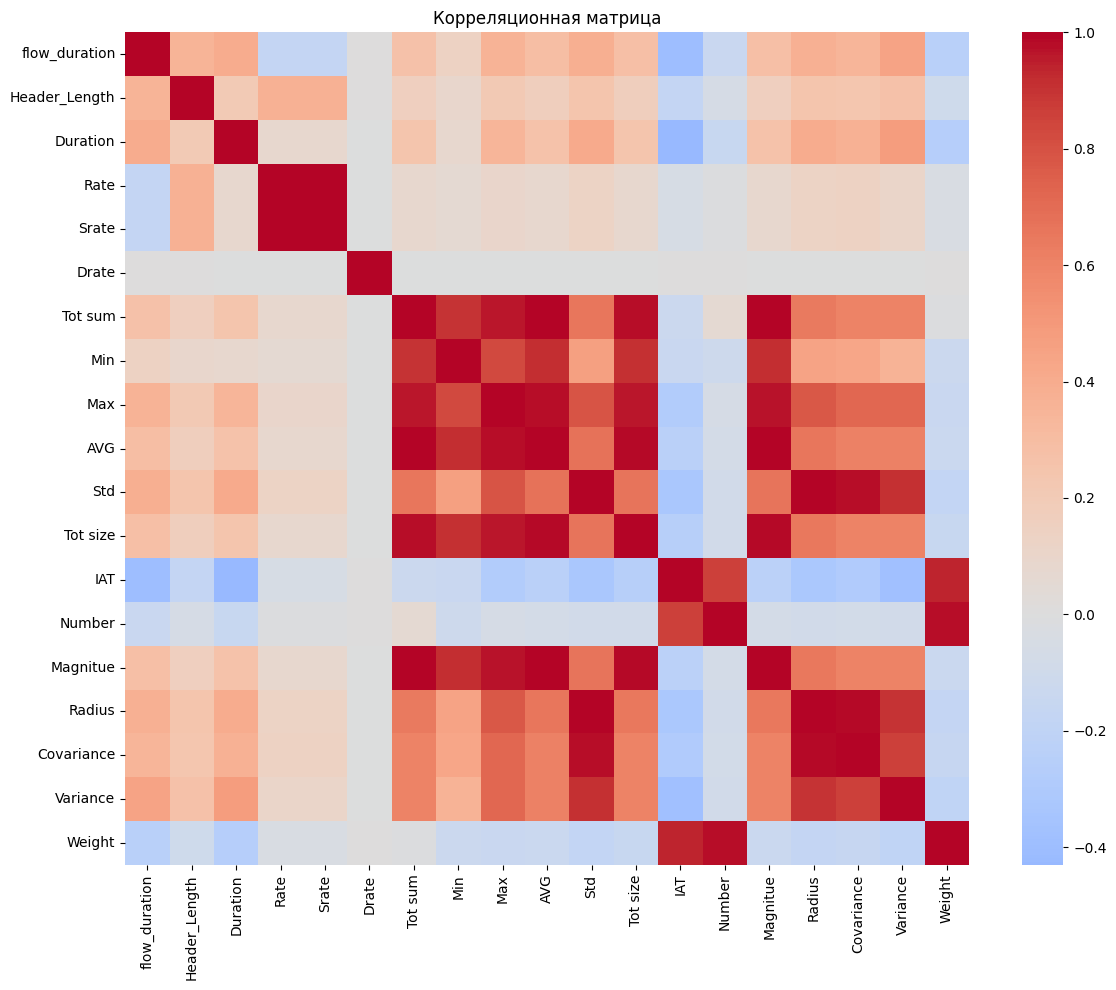

Rate ~ Srate: 1.000
Min ~ Tot size: 0.911
Max ~ Tot sum: 0.965
Max ~ Tot size: 0.961
AVG ~ Tot sum: 0.991
AVG ~ Min: 0.915
AVG ~ Max: 0.972
AVG ~ Tot size: 0.988
AVG ~ Magnitue: 0.999
Std ~ Variance: 0.907
Tot size ~ Tot sum: 0.978
IAT ~ Weight: 0.937
Number ~ Weight: 0.982
Magnitue ~ Tot sum: 0.991
Magnitue ~ Min: 0.917
Magnitue ~ Max: 0.967
Magnitue ~ Tot size: 0.986
Radius ~ Std: 0.998
Radius ~ Variance: 0.904
Covariance ~ Std: 0.981
Covariance ~ Radius: 0.989


In [62]:
num_for_corr = ["flow_duration", "Header_Length", "Duration", "Rate", "Srate", "Drate",
    "Tot sum", "Min", "Max", "AVG", "Std", "Tot size", "IAT",
    "Number", "Magnitue", "Radius", "Covariance", "Variance", "Weight"]

corr_sample = df.select(num_for_corr).sample(fraction=0.05, seed=42).toPandas()
corr = corr_sample.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

# пары с |corr| > 0.9
high = [(i, j, corr.loc[i, j]) for i in corr.columns for j in corr.columns
        if i < j and abs(corr.loc[i, j]) > 0.9]
for i, j, v in high:
    print(f"{i} ~ {j}: {v:.3f}")

Из тепловой карты мы видим: \
1. Rate ~ Srate: 1.000, мы уже увидели, что это повторяющийся столбец \ 
2. AVG ↔ Magnitue = 0.999, Если поток однонаправленный, то по формуле все сходится \ 
3. Группа «длина пакета» +- похожи друг на друга \
4. IAT ↔ Weight = 0.937, чем больше пакетов, тем плотнее они идут, тем меньше IAT

Посмотрим на распределение некоторых признаков

/tmp/ipykernel_1369781/2956525884.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, vert=True, patch_artist=True,


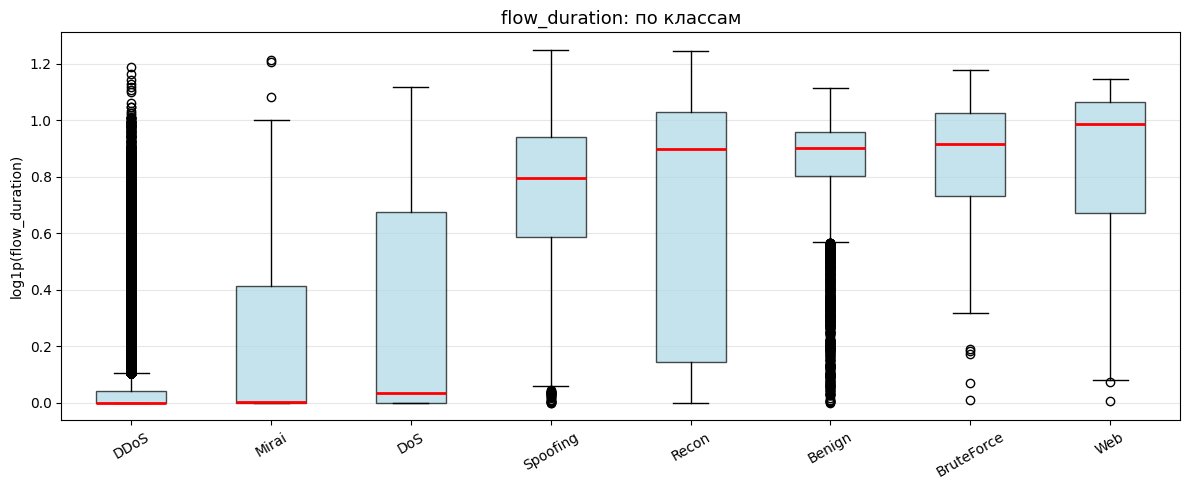

/tmp/ipykernel_1369781/2956525884.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, vert=True, patch_artist=True,


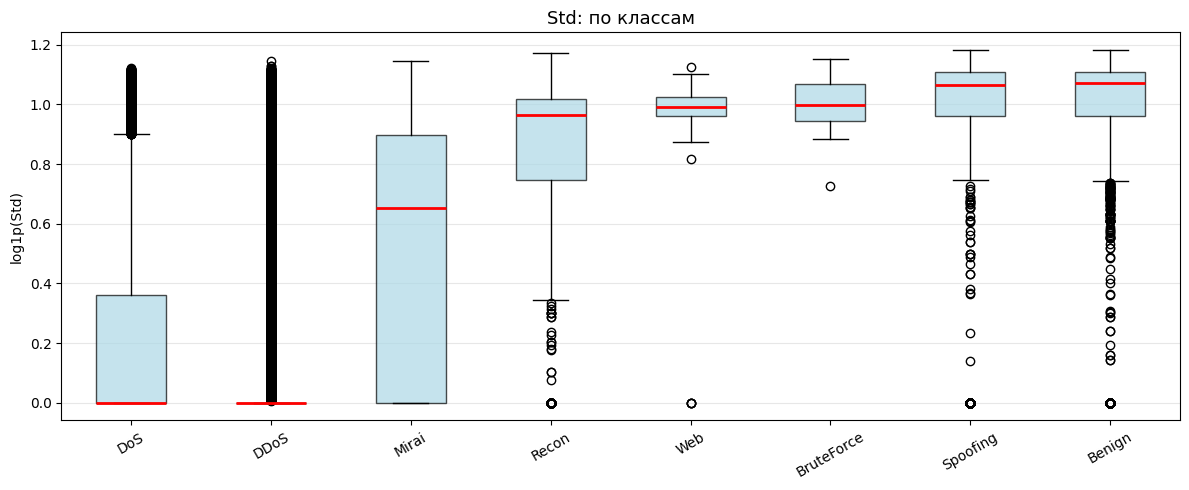

/tmp/ipykernel_1369781/2956525884.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, vert=True, patch_artist=True,


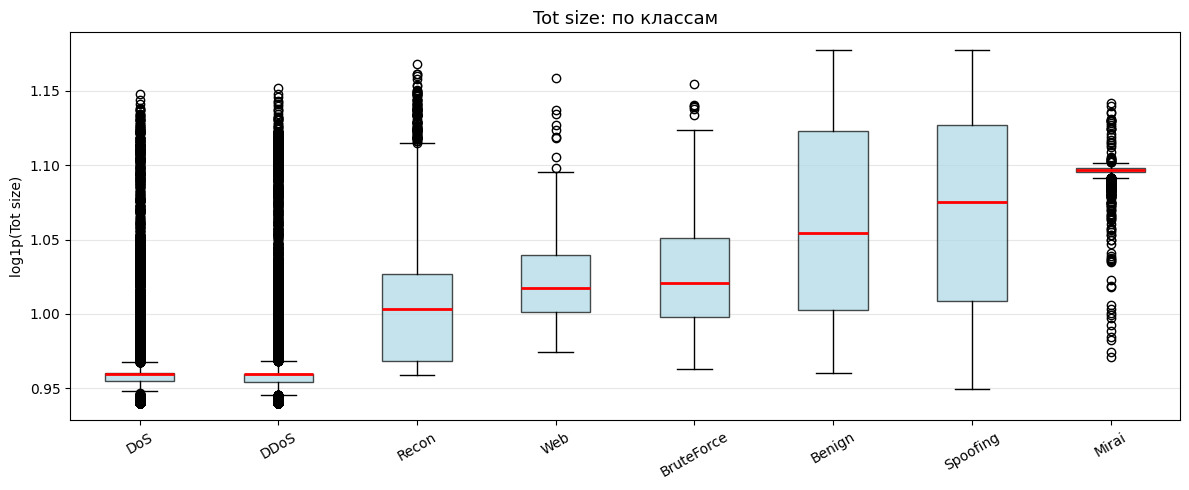

/tmp/ipykernel_1369781/2956525884.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, vert=True, patch_artist=True,


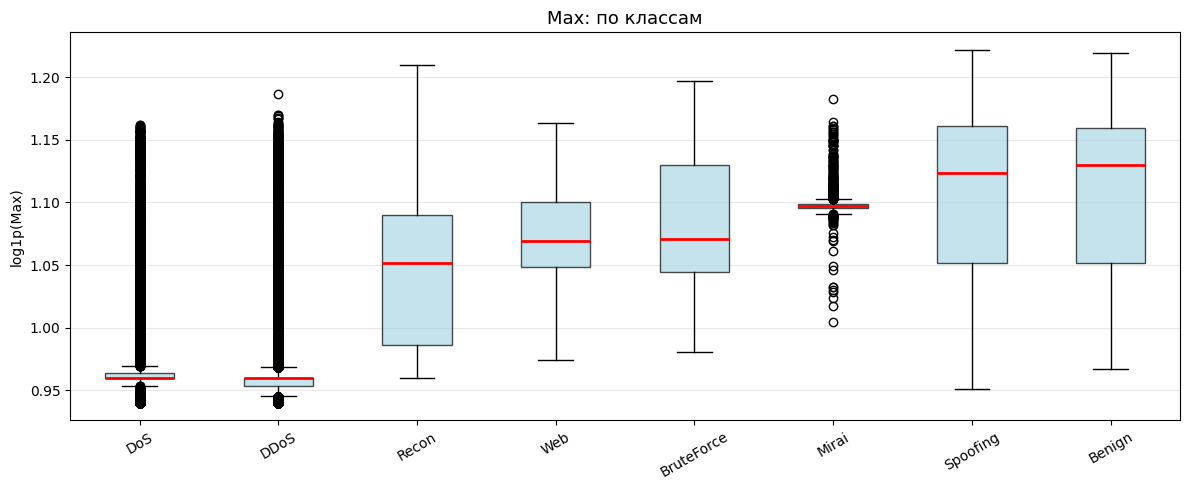

/tmp/ipykernel_1369781/2956525884.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, vert=True, patch_artist=True,


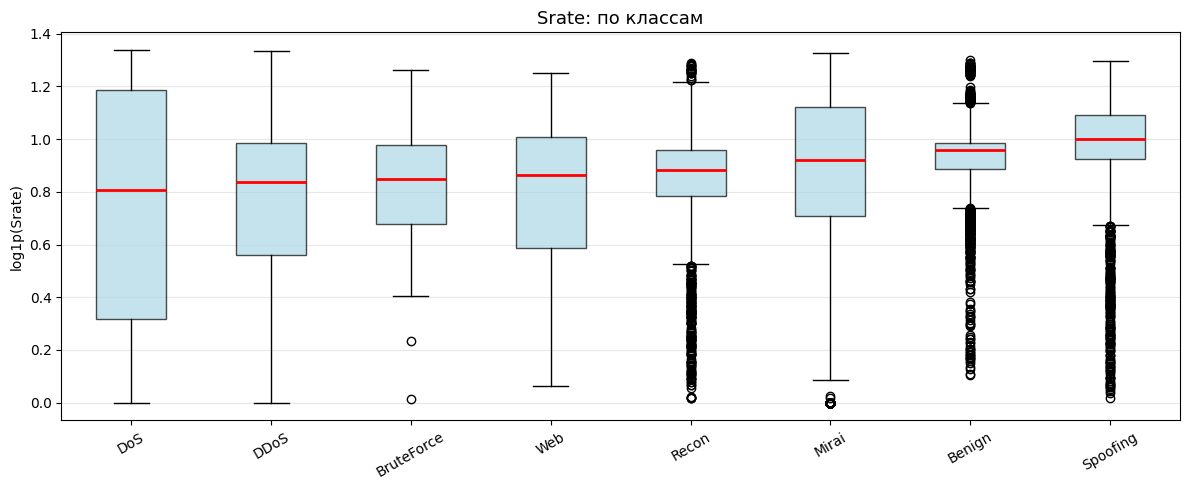

In [64]:


def boxplot_by_class(df, col, frac=0.02, seed=42, log=True):
    sample = df.select(col, "label").sample(fraction=frac, seed=seed).toPandas()
    sample = sample.dropna(subset=[col])

    if log and sample[col].min() >= 0:
        sample["x"] = np.log1p(sample[col])
        ylabel = f"log1p({col})"
    else:
        sample["x"] = sample[col]
        ylabel = col

    # сортировка классов по медиане
    order = sample.groupby("label")["x"].median().sort_values().index

    fig, ax = plt.subplots(figsize=(12, 5))
    data = [sample.loc[sample["label"] == lbl, "x"].values for lbl in order]
    ax.boxplot(data, labels=order, vert=True, patch_artist=True,
               boxprops=dict(facecolor="lightblue", alpha=0.7),
               medianprops=dict(color="red", linewidth=2))
    ax.set_title(f"{col}: по классам", fontsize=13)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

for c in ["flow_duration", "Std", "Tot size", "Max", "Srate"]:
    boxplot_by_class(df, c)